In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
df = pd.read_csv('/content/telco_customer_churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)

df['Churn_Flag'] = df['Churn'].map({'Yes': 1, 'No': 0})

baseline_churn = df['Churn_Flag'].mean() * 100
print(f"Baseline Churn Rate: {baseline_churn:.2f}%")

Baseline Churn Rate: 26.58%


=== Cohort Retention Matrix (%) ===
Contract       Month-to-month  One year  Two year
Tenure_Cohort                                    
0-12 Months             48.65     89.43    100.00
13-24 Months            62.28     91.88    100.00
25-36 Months            67.49     92.00     97.92
37-48 Months            66.46     86.94     97.75
49-60 Months            72.22     86.29     96.03
61-72 Months            77.78     87.86     96.86


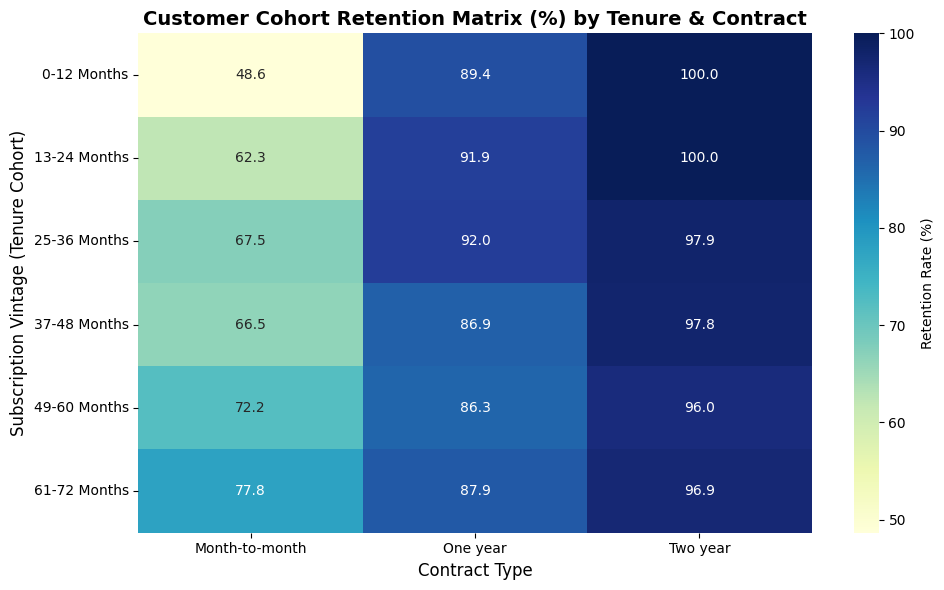


=== Top 5 High-Risk Churn Segments ===
   InternetService TechSupport              PaymentMethod  count  Churn_Rate_%
10     Fiber optic          No           Electronic check   1288         58.07
11     Fiber optic          No               Mailed check    185         49.73
2              DSL          No           Electronic check    442         38.91
8      Fiber optic          No  Bank transfer (automatic)    400         36.50
14     Fiber optic         Yes           Electronic check    307         32.90


In [2]:
bins = [0, 12, 24, 36, 48, 60, 72]
labels = ['0-12 Months', '13-24 Months', '25-36 Months', '37-48 Months', '49-60 Months', '61-72 Months']
df['Tenure_Cohort'] = pd.cut(df['tenure'], bins=bins, labels=labels, include_lowest=True)
cohort_churn = df.groupby(['Tenure_Cohort', 'Contract'], observed=False)['Churn_Flag'].mean().unstack() * 100
retention_matrix = 100 - cohort_churn
print("=== Cohort Retention Matrix (%) ===")
print(retention_matrix.round(2))
plt.figure(figsize=(10, 6))
sns.heatmap(retention_matrix, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Retention Rate (%)'})
plt.title('Customer Cohort Retention Matrix (%) by Tenure & Contract', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Subscription Vintage (Tenure Cohort)', fontsize=12)
plt.tight_layout()
plt.savefig('cohort_retention_matrix.png', dpi=300)
plt.show()
retention_curve = df.groupby('tenure')['Churn_Flag'].apply(lambda x: (1 - x.mean()) * 100).reset_index()
retention_curve.columns = ['Tenure_Months', 'Retention_Rate']

fig1 = px.line(retention_curve, x='Tenure_Months', y='Retention_Rate',
               title='Customer Retention Curve Over Tenure (Months)',
               labels={'Tenure_Months': 'Tenure (Months)', 'Retention_Rate': 'Retention Rate (%)'})
fig1.show()
high_risk = df.groupby(['InternetService', 'TechSupport', 'PaymentMethod'])['Churn_Flag'].agg(['count', 'mean']).reset_index()
high_risk['Churn_Rate_%'] = (high_risk['mean'] * 100).round(2)
high_risk = high_risk.sort_values(by='Churn_Rate_%', ascending=False)

print("\n=== Top 5 High-Risk Churn Segments ===")
print(high_risk[['InternetService', 'TechSupport', 'PaymentMethod', 'count', 'Churn_Rate_%']].head(5))